# Most Common Apps by Genre
- Will determine the most common apps by genre for each store

In [29]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from csv import reader

In [2]:
# Storing the cleaned data into two new pandas dataframes

gplay_data = pd.read_csv("cleaned_data/gplay_cleaned.csv")
ios_data = pd.read_csv("cleaned_data/ios_cleaned.csv")

In [15]:
top_gplay = (
    gplay.sort_values(["Genres", "Installs"], ascending=[True, False])
    .drop_duplicates(subset=["Genres", "App"])
    .groupby("Genres", sort=False)
    .head(5)[["Genres", "App", "Installs"]]
)

top_gplay

,Genres,App,Installs
1352,Action,Temple Run 2,"500,000,000+"
3593,Action,Hide N Seek : Mini Game,"500,000+"
3810,Action,The Gang Sniper V. Pocket Edition.,"500,000+"
3894,Action,Hero Fighter X,"500,000+"
3947,Action,Rage Z: Multiplayer Zombie FPS Online Shooter,"500,000+"
...,...,...,...
5169,Word,Word Hunt,500+
1669,Word,Word Search,"50,000,000+"
3846,Word,Words With Friends Classic,"50,000,000+"
3868,Word,Draw Something Classic,"50,000,000+"


In [10]:
top_ios = (
    ios_data.sort_values("rating_count_tot", ascending=False)
    .groupby("prime_genre", sort=False)
    .head(5)[["prime_genre", "track_name", "rating_count_tot"]]
)

top_ios

,prime_genre,track_name,rating_count_tot
0,Social Networking,Facebook,2974676
1,Photo & Video,Instagram,2161558
2,Games,Clash of Clans,2130805
3,Games,Temple Run,1724546
4,Music,Pandora - Music & Radio,1126879
...,...,...,...
2004,Catalogs,Face Swap and Copy Free – Switch & Fusion Face...,431
2281,Catalogs,Ringtone Remixes - Marimba Remix Ringtones,213
2322,Navigation,ImmobilienScout24: Real Estate Search in Germany,187
2853,Medical,MyDx One: Find a Strain that Works for You,29


In [25]:
gplay_top_genres = (
    gplay_data["Genres"]
    .str.split(";")
    .explode()
    .value_counts()
    .head(5)
)
# apps can have multipl genres separated by ";" so this code splits the genres so each can be counted

print("Top 5 Google Play Genres: ")
print(gplay_top_genres)

Top 5 Google Play Genres: 
Genres
Tools            670
Education        569
Entertainment    522
Action           337
Productivity     315
Name: count, dtype: int64


In [28]:
ios_top_genres = ios_data["prime_genre"].value_counts().head(5)
ios_top_genres

prime_genre
Games                1874
Entertainment         254
Photo & Video         160
Education             118
Social Networking     106
Name: count, dtype: int64

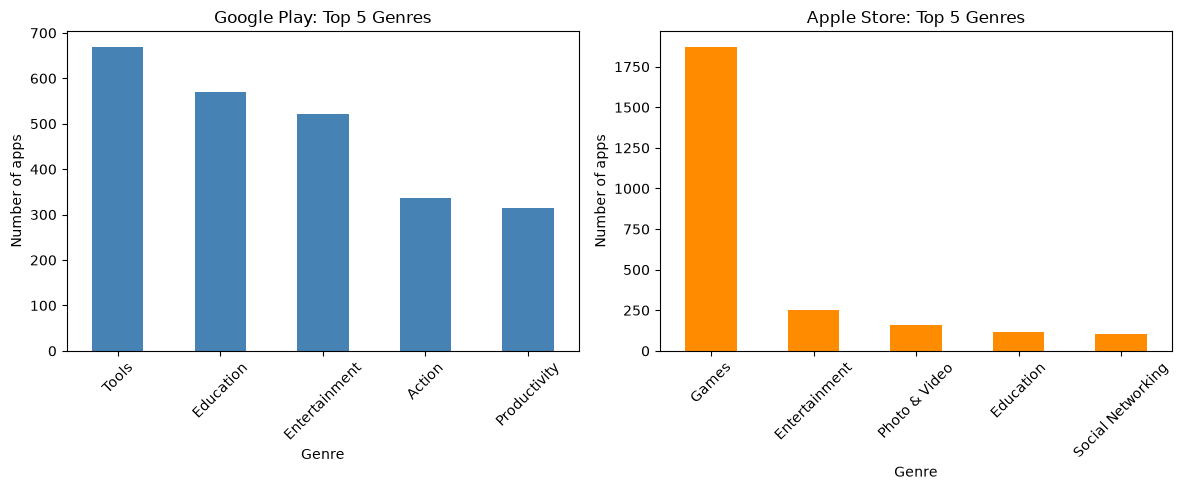

In [33]:
import matplotlib.pyplot as plt

# Count Google Play apps by genre (some rows list multiple genres)
gplay_top5 = (
    gplay_data["Genres"]
    .str.split(";")
    .explode()
    .value_counts()
    .head(5)
)

# Count Apple apps by genre
apple_top5 = ios_data["prime_genre"].value_counts().head(5)

# Plot them side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

gplay_top5.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Google Play: Top 5 Genres")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Number of apps")
axes[0].tick_params(axis="x", rotation=45)

apple_top5.plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Apple Store: Top 5 Genres")
axes[1].set_xlabel("Genre")
axes[1].set_ylabel("Number of apps")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("charts/top_5_genres.png", dpi = 300)
plt.show()

plt.close()